# Introdução ao Machine Learning Aplicado com Scikit-learn e NumPy

## Importação do dataset

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ID da planilha pública
sheet_id = "1iXHJ5T8qz4ef_vJF65fvr1b_DU0H0wXUjWd0vsa2GIs"
# GID da página 'dados_emprestimo'
gid = "702154315"

# URL para exportação direta em CSV pura (sem passar pelo Excel)
url_csv = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"

# Caminho do arquivo CSV local no Colab
caminho_local_csv = "dados_emprestimo_sujos.csv"

if not os.path.exists(caminho_local_csv):
    print("Baixando o dataset em formato csv...")
    try:
        import urllib.request
        urllib.request.urlretrieve(url_csv, caminho_local_csv)
        print("Download do CSV concluído com sucesso!")
    except Exception as e:
        print("Erro ao baixar o CSV:")
        print(e)

# Importando o arquivo CSV salvo localmente
try:
    df = pd.read_csv(caminho_local_csv)
    print(f"Dataset carregado com sucesso! Formato: {df.shape}")
except Exception as e:
    print("Erro ao ler o arquivo CSV local:")
    print(e)

Dataset carregado com sucesso! Formato: (45450, 15)


In [14]:
    display(df.head())
    display(df.info())

,cpf,idade_pessoa,genero_pessoa,escolaridade_pessoa,renda_pessoa,tempo_emprego_pessoa,posse_imovel_pessoa,valor_emprestimo,motivo_emprestimo,taxa_juros_emprestimo,percentual_renda_emprestimo,tempo_historico_credito,pontuacao_credito,historico_inadimplencia,status_emprestimo
0,188.484.189-89,22,feminino,Mestrado,71948.0,0.0,ALUGUEL,35000,PESSOAL,16.02,0.49,3,561,Não,1
1,107.460.977-75,21,feminino,Ensino Médio,12282.0,0.0,PRÓPRIO,1000,EDUCAÇÃO,11.14,0.08,2,504,Sim,0
2,170.851.886-07,25,feminino,Ensino Médio,12438.0,3.0,FINANCIADO,5500,MÉDICO,12.87,0.44,3,635,Não,1
3,278.075.874-95,23,feminino,Bacharelado,79753.0,0.0,ALUGUEL,35000,MÉDICO,15.23,0.44,2,675,Não,1
4,125.298.774-79,24,masculino,Mestrado,66135.0,1.0,ALUGUEL,35000,MÉDICO,14.27,0.53,4,586,Não,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45450 entries, 0 to 45449
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cpf                          45450 non-null  object 
 1   idade_pessoa                 45450 non-null  int64  
 2   genero_pessoa                45450 non-null  object 
 3   escolaridade_pessoa          44530 non-null  object 
 4   renda_pessoa                 44597 non-null  float64
 5   tempo_emprego_pessoa         44571 non-null  float64
 6   posse_imovel_pessoa          44520 non-null  object 
 7   valor_emprestimo             45450 non-null  int64  
 8   motivo_emprestimo            45450 non-null  object 
 9   taxa_juros_emprestimo        45450 non-null  float64
 10  percentual_renda_emprestimo  45450 non-null  float64
 11  tempo_historico_credito      45450 non-null  int64  
 12  pontuacao_credito            45450 non-null  int64  
 13  historico_inadim

None

##  Pré-processamento dos Dados

In [15]:
#@title Análise inicial
print("Valores nulos por coluna:")
print(df.isnull().sum())
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")


Valores nulos por coluna:
cpf                              0
idade_pessoa                     0
genero_pessoa                    0
escolaridade_pessoa            920
renda_pessoa                   853
tempo_emprego_pessoa           879
posse_imovel_pessoa            930
valor_emprestimo                 0
motivo_emprestimo                0
taxa_juros_emprestimo            0
percentual_renda_emprestimo      0
tempo_historico_credito          0
pontuacao_credito                0
historico_inadimplencia          0
status_emprestimo                0
dtype: int64

Linhas duplicadas: 450


In [25]:
#@title limpeza

df = df.dropna()
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Valores nulos por coluna:")
print(df.isnull().sum())
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")

Valores nulos por coluna:
cpf                            0
idade_pessoa                   0
genero_pessoa                  0
escolaridade_pessoa            0
renda_pessoa                   0
tempo_emprego_pessoa           0
posse_imovel_pessoa            0
valor_emprestimo               0
motivo_emprestimo              0
taxa_juros_emprestimo          0
percentual_renda_emprestimo    0
tempo_historico_credito        0
pontuacao_credito              0
historico_inadimplencia        0
status_emprestimo              0
cluster                        0
dtype: int64

Linhas duplicadas: 0


### Codificação e Padronização

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# ---- DEFINIÇÃO DAS COLUNAS E ORDENS ----
colunas_ordinais = ['escolaridade_pessoa']
ordem_escolaridade = [
    ['Ensino Médio', 'Tecnólogo', 'Bacharelado', 'Mestrado', 'Doutorado']
]

colunas_categoricas = [
    'genero_pessoa',
    'posse_imovel_pessoa',
    'motivo_emprestimo',
    'historico_inadimplencia',
]

colunas_numericas = [
    'idade_pessoa',
    'renda_pessoa',
    'tempo_emprego_pessoa',
    'valor_emprestimo',
    'taxa_juros_emprestimo',
    'percentual_renda_emprestimo',
    'tempo_historico_credito',
    'pontuacao_credito',
]

# Separa X e y
X = df.drop('status_emprestimo', axis=1)
y = df['status_emprestimo']

# ---- DIVISÃO ÚNICA (Hold-Out) ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---- PRÉ-PROCESSADOR ÚNICO ATUALIZADO ----
preprocessor = ColumnTransformer(
    transformers=[
        ('ord',OrdinalEncoder(categories=ordem_escolaridade),colunas_ordinais),
        ('cat', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
        ('num', StandardScaler(), colunas_numericas),
    ]
)

# Ajusta SÓ no treino (evita data leakage)
preprocessor.fit(X_train)

# Transforma treino e teste com o mesmo pré-processador
X_train_transformado = preprocessor.transform(X_train)
X_test_transformado = preprocessor.transform(X_test)

colunas_transformadas = preprocessor.get_feature_names_out()

print('\n--- ANTES (Dados Brutos) ---')
display(X_train.head(3))

print('\n--- DEPOIS (Dados Transformados) ---')
display(pd.DataFrame(X_train_transformado[:3], columns=colunas_transformadas))

print(f'\nShape X_train: {X_train.shape} -> {X_train_transformado.shape}')
print(f'Shape X_test:  {X_test.shape}  -> {X_test_transformado.shape}')


--- ANTES (Dados Brutos) ---


,cpf,idade_pessoa,genero_pessoa,escolaridade_pessoa,renda_pessoa,tempo_emprego_pessoa,posse_imovel_pessoa,valor_emprestimo,motivo_emprestimo,taxa_juros_emprestimo,percentual_renda_emprestimo,tempo_historico_credito,pontuacao_credito,historico_inadimplencia
22873,217.270.540-75,34,feminino,Tecnólogo,90967.0,10.0,FINANCIADO,6500,CONSOLIDAÇÃO_DÍVIDA,9.38,0.07,7,659,Sim
20198,579.990.266-44,31,feminino,Ensino Médio,87585.0,9.0,ALUGUEL,6000,REFORMA_CASA,13.23,0.07,5,616,Sim
40531,449.398.947-05,24,feminino,Ensino Médio,35551.0,2.0,ALUGUEL,7444,MÉDICO,11.20,0.21,4,644,Não



--- DEPOIS (Dados Transformados) ---


,ord__escolaridade_pessoa,cat__genero_pessoa_feminino,cat__genero_pessoa_masculino,cat__posse_imovel_pessoa_ALUGUEL,cat__posse_imovel_pessoa_FINANCIADO,cat__posse_imovel_pessoa_OUTRO,cat__posse_imovel_pessoa_PRÓPRIO,cat__motivo_emprestimo_CONSOLIDAÇÃO_DÍVIDA,cat__motivo_emprestimo_EDUCAÇÃO,cat__motivo_emprestimo_EMPREENDIMENTO,...,cat__historico_inadimplencia_Não,cat__historico_inadimplencia_Sim,num__idade_pessoa,num__renda_pessoa,num__tempo_emprego_pessoa,num__valor_emprestimo,num__taxa_juros_emprestimo,num__percentual_renda_emprestimo,num__tempo_historico_credito,num__pontuacao_credito
0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,1.039053,0.121801,0.765276,-0.488753,-0.545914,-0.799661,0.298448,0.529512
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.541517,0.082612,0.599651,-0.568171,0.747935,-0.799661,-0.221449,-0.323037
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.619401,-0.520330,-0.559729,-0.338812,0.065724,0.798843,-0.481397,0.232111



Shape X_train: (33240, 14) -> (33240, 23)
Shape X_test:  (8310, 14)  -> (8310, 23)


### Padronização X Normalização

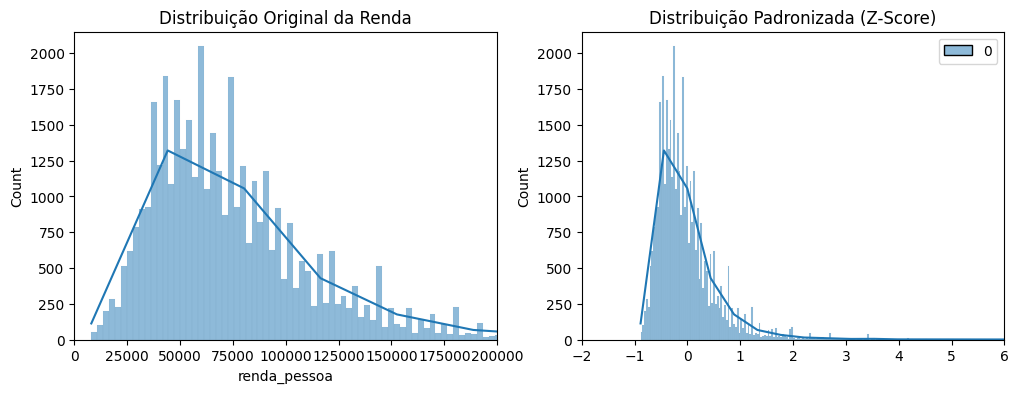

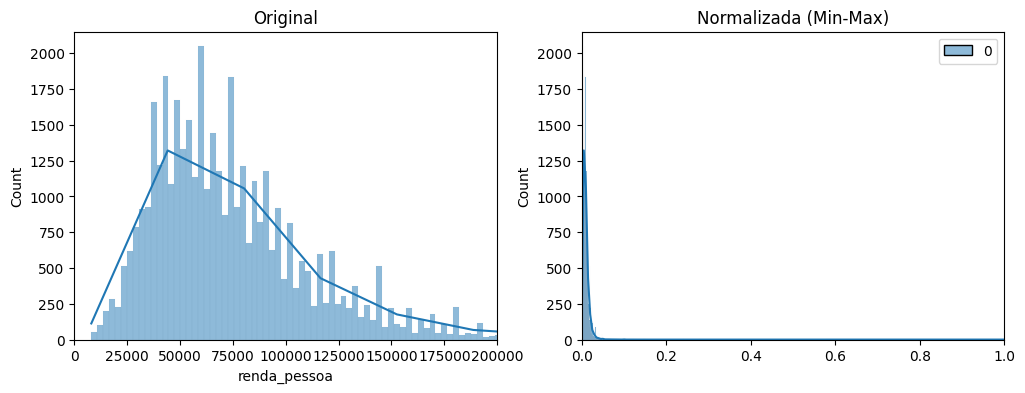

In [18]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['renda_pessoa'], kde=True)
plt.title('Distribuição Original da Renda')
plt.xlim(0, 200000)

plt.subplot(1, 2, 2)
renda_padronizada = StandardScaler().fit_transform(df[['renda_pessoa']])
sns.histplot(renda_padronizada, kde=True)
plt.title('Distribuição Padronizada (Z-Score)')
plt.xlim(-2, 6)
plt.show()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['renda_pessoa'], kde=True)
plt.title('Original')
plt.xlim(0, 200000)

plt.subplot(1, 2, 2)
renda_normalizada = MinMaxScaler().fit_transform(df[['renda_pessoa']])
sns.histplot(renda_normalizada, kde=True)
plt.title('Normalizada (Min-Max)')
plt.xlim(0, 1)
plt.show()

## Aprendizado Supervisionado

Relatório - KNN:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      6455
           1       0.78      0.70      0.73      1855

    accuracy                           0.89      8310
   macro avg       0.85      0.82      0.83      8310
weighted avg       0.88      0.89      0.89      8310

Relatório - Naive Bayes:
              precision    recall  f1-score   support

           0       1.00      0.65      0.79      6455
           1       0.45      1.00      0.62      1855

    accuracy                           0.73      8310
   macro avg       0.73      0.83      0.71      8310
weighted avg       0.88      0.73      0.75      8310

Relatório - Árvore de Decisão:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      6455
           1       0.75      0.77      0.76      1855

    accuracy                           0.89      8310
   macro avg       0.84      0.85      0.84      8310
w

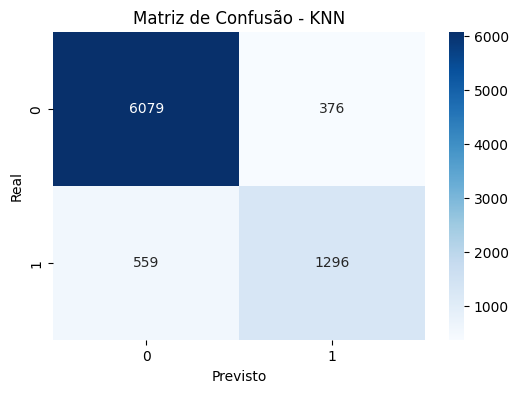

Comparação de Acurácia (mesmo X_test):
  KNN: 0.887
  Naive Bayes: 0.730
  Árvore de Decisão: 0.891
  Floresta Aleatória: 0.922


In [19]:
#supervisionado
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Função auxiliar: cria pipeline reutilizando o preprocessor já ajustado
def criar_pipeline(classificador):
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classificador)
    ])

pipeline_knn = criar_pipeline(KNeighborsClassifier(n_neighbors=5))
pipeline_nb  = criar_pipeline(GaussianNB())
pipeline_dt  = criar_pipeline(DecisionTreeClassifier(random_state=42))
pipeline_rf  = criar_pipeline(RandomForestClassifier(random_state=42))

# ---- Treina e avalia cada modelo ----
pipeline_knn.fit(X_train, y_train); y_pred    = pipeline_knn.predict(X_test)
pipeline_nb.fit(X_train, y_train);  y_pred_nb = pipeline_nb.predict(X_test)
pipeline_dt.fit(X_train, y_train);  y_pred_dt = pipeline_dt.predict(X_test)
pipeline_rf.fit(X_train, y_train);  y_pred_rf = pipeline_rf.predict(X_test)

# ---- Relatórios ----
print("Relatório - KNN:")
print(classification_report(y_test, y_pred))

print("Relatório - Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

print("Relatório - Árvore de Decisão:")
print(classification_report(y_test, y_pred_dt))

print("Relatório - Floresta Aleatória:")
print(classification_report(y_test, y_pred_rf))

# ---- Matriz de Confusão KNN ----
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - KNN')
plt.xlabel('Previsto'); plt.ylabel('Real')
plt.show()

# ---- Comparação de Acurácia ----
modelos_pred = {
    'KNN': y_pred,
    'Naive Bayes': y_pred_nb,
    'Árvore de Decisão': y_pred_dt,
    'Floresta Aleatória': y_pred_rf,
}
print("Comparação de Acurácia (mesmo X_test):")
for nome, pred in modelos_pred.items():
    print(f"  {nome}: {accuracy_score(y_test, pred):.3f}")


In [20]:
# =========================================================
# BLOCO 4 — EXERCÍCIO: Ajuste de hiperparâmetros
# =========================================================
# for k in [3, 5, 7, 11, 15]:
#     pipe = criar_pipeline(KNeighborsClassifier(n_neighbors=k))
#     pipe.fit(X_train, y_train)
#     acc = accuracy_score(y_test, pipe.predict(X_test))
#     print(f"K={k}: Acurácia = {acc:.3f}")

## Aprendizado Não Supervisionado

K-Means aplicado!
Centroides:
[[-3.26001888e-01 -6.57228391e-02 -3.22238429e-01 -5.20426904e-01
  -1.88664586e-01 -4.94057857e-01 -3.18368738e-01 -7.16988954e-02]
 [ 1.89393101e+00  2.77395240e-01  1.88613134e+00  9.09331701e-03
   2.83504324e-02 -1.53432030e-01  1.84401547e+00  3.92468740e-01]
 [-2.45034314e-01  1.29909021e-04 -2.48876333e-01  1.03854483e+00
   3.64609016e-01  1.06279113e+00 -2.36655014e-01 -4.24744451e-02]]


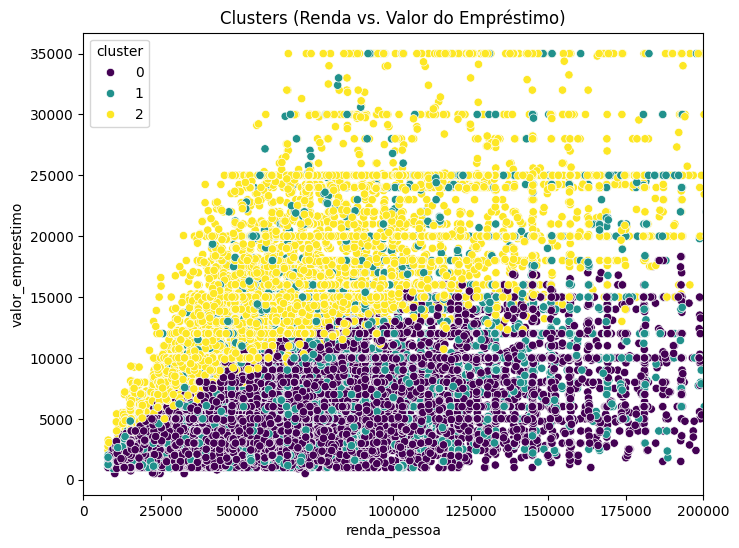

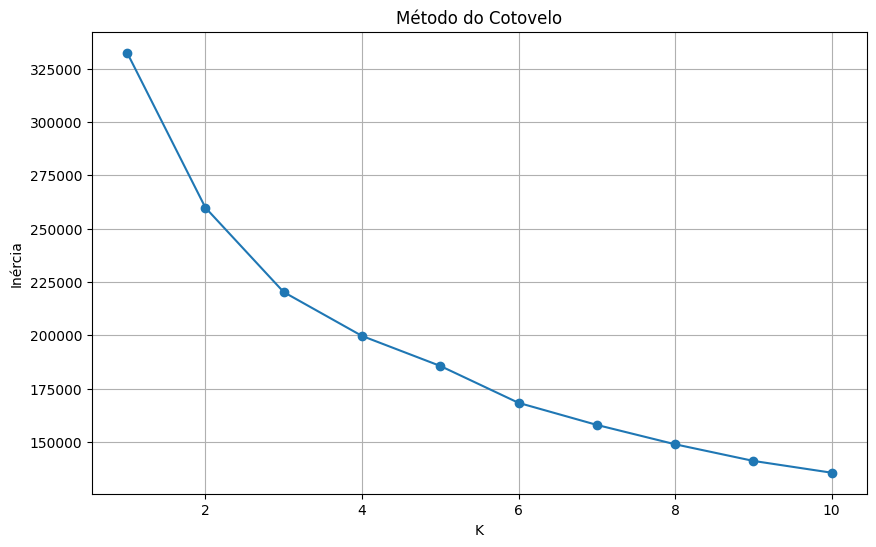

In [21]:
#nao supervisionado

from sklearn.cluster import KMeans

# Cópia do df antes de adicionar a coluna 'cluster'
df_original = df.copy()

# Apenas numéricas, padronizadas
X_cluster = df[colunas_numericas]
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

# K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_cluster_scaled)
df['cluster'] = kmeans.labels_

print("K-Means aplicado!")
print(f"Centroides:\n{kmeans.cluster_centers_}")

# Visualização
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='renda_pessoa', y='valor_emprestimo',
                hue='cluster', palette='viridis')
plt.title('Clusters (Renda vs. Valor do Empréstimo)')
plt.xlim(0, 200000)
plt.show()

# ---- Método do Cotovelo ----
inercia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inercia.append(km.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inercia, marker='o')
plt.title('Método do Cotovelo')
plt.xlabel('K'); plt.ylabel('Inércia')
plt.grid(True); plt.show()

In [22]:
#EXERCÍCIO: Interpretação dos clusters
# analise = df.groupby('cluster')[colunas_numericas].mean()
# display(analise)

In [23]:
#validação

# 7.1 Hold-Out já foi feito no Bloco 2.
# Se quiser um conjunto de VALIDAÇÃO, separe a partir do TREINO (nunca do teste):
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print(f"Treino final: {X_train_final.shape}")
print(f"Validação:    {X_val.shape}")
print(f"Teste:        {X_test.shape}  # intocado")

# 7.2 Validação Cruzada — usa X_train (NÃO o X completo!)
from sklearn.model_selection import cross_val_score

scores = cross_val_score(pipeline_knn, X_train, y_train, cv=5, scoring='accuracy')
print(f"Scores por fold: {scores}")
print(f"Média: {scores.mean():.3f}")
print(f"Desvio padrão: {scores.std():.3f}")

Treino final: (26592, 14)
Validação:    (6648, 14)
Teste:        (8310, 14)  # intocado
Scores por fold: [0.89951865 0.90252708 0.89365223 0.89605897 0.89651023]
Média: 0.898
Desvio padrão: 0.003


In [24]:
#EXERCÍCIO: CV em múltiplos modelos


modelos_cv = {
    'KNN': pipeline_knn,
    'Naive Bayes': pipeline_nb,
    'Árvore de Decisão': pipeline_dt,
    'Floresta Aleatória': pipeline_rf,
}

resultados = {}
for nome, pipe in modelos_cv.items():
    s = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    resultados[nome] = (s.mean(), s.std())
    print(f"{nome}: média={s.mean():.3f}, desvio={s.std():.3f}")

melhor = max(resultados, key=lambda k: resultados[k][0])
mais_estavel = min(resultados, key=lambda k: resultados[k][1])
print(f"\n Melhor média: {melhor}")
print(f" Mais estável: {mais_estavel}")

KNN: média=0.898, desvio=0.003
Naive Bayes: média=0.735, desvio=0.002
Árvore de Decisão: média=0.898, desvio=0.002
Floresta Aleatória: média=0.929, desvio=0.002

 Melhor média: Floresta Aleatória
 Mais estável: Floresta Aleatória
